# 01 — Simple Linear Regression (SLR)


**Dataset:** `Practical_Dataset for ML.xlsx` (worksheet `Data`)  
**Target:** `price_etb`  
**Split:** 80% training / 20% test, `random_state=42`

## Learning objectives
- Understand a feature, target, fitted line, slope, and intercept.
- Fit a simple linear regression using one predictor.
- Evaluate training and test performance.
- Visualize predictions and residuals.

## 1. Import libraries

In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = "price_etb"
FEATURE = "size_sqm"

## 2. Load the Excel dataset

The notebook checks common project locations. If your workbook is stored elsewhere, edit `DATA_PATH`.

In [23]:
possible_paths = [
    Path("data") / "Practical_Dataset for ML.xlsx",
    Path("ML_Course") / "data" / "Practical_Dataset for ML.xlsx",
    Path("..") / "data" / "Practical_Dataset for ML.xlsx",
    Path("..") / ".." / "data" / "Practical_Dataset for ML.xlsx",
    Path("Practical_Dataset for ML.xlsx"),
]
DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Workbook not found. Put 'Practical_Dataset for ML.xlsx' in the data/ folder "
        "or set DATA_PATH to its full path."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df[[TARGET, FEATURE]].describe())

Loaded: ..\..\data\Practical_Dataset for ML.xlsx
Dataset shape: (3000, 17)


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


,price_etb,size_sqm
count,3.000000e+03,3000.000000
mean,6.000234e+06,140.666033
std,4.914972e+06,90.250804
min,5.560000e+05,32.000000
25%,2.872500e+06,79.800000
50%,4.378000e+06,111.100000
75%,7.321500e+06,176.625000
max,4.097300e+07,572.400000


## 3. Select the feature and target

Simple linear regression uses exactly one predictor. Here, `size_sqm` predicts `price_etb`.

In [24]:
required = {TARGET, FEATURE}
missing = required - set(df.columns)
if missing:
    raise KeyError(f"Missing required columns: {missing}. Available columns: {list(df.columns)}")

data = df[[FEATURE, TARGET]].copy()
data[FEATURE] = pd.to_numeric(data[FEATURE], errors="coerce")
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
data = data.dropna()

X = data[[FEATURE]]
y = data[TARGET]

print("Rows after removing missing/non-numeric values:", len(data))
print("Feature:", FEATURE)
print("Target:", TARGET)

Rows after removing missing/non-numeric values: 3000
Feature: size_sqm
Target: price_etb


## 4. Split into training and test sets

The training set is used to fit the line. The test set estimates performance on unseen observations.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")

Training rows: 2,400
Test rows: 600


## 5. Train the model

The fitted equation is \(\hat{y}=b_0+b_1x\), where \(b_0\) is the intercept and \(b_1\) is the slope.

In [26]:
slr = LinearRegression()
slr.fit(X_train, y_train)

intercept = float(slr.intercept_)
slope = float(slr.coef_[0])

print(f"Intercept (b0): {intercept:,.4f}")
print(f"Slope (b1): {slope:,.4f}")
print(f"Fitted equation: predicted price_etb = {intercept:,.2f} + ({slope:,.2f} × size_sqm)")

Intercept (b0): -678,255.1102
Slope (b1): 47,363.0466
Fitted equation: predicted price_etb = -678,255.11 + (47,363.05 × size_sqm)


## 6. Evaluate the model

MAE, MSE and RMSE measure prediction error (lower is better). R² measures the proportion of target variation explained by the model; test R² can be negative.

In [27]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

train_pred = slr.predict(X_train)
test_pred = slr.predict(X_test)

results = pd.DataFrame([
    {"Dataset": "Train", **metrics(y_train, train_pred)},
    {"Dataset": "Test", **metrics(y_test, test_pred)},
])
display(results.round(4))

,Dataset,MAE,MSE,RMSE,R2
0,Train,1.485776e+06,5.263627e+12,2294259.610,0.7759
1,Test,1.603659e+06,6.987126e+12,2643317.179,0.7388


## 7. Visualize the fitted line

The scatter plot shows observed values; the line shows the relationship learned from the training data.

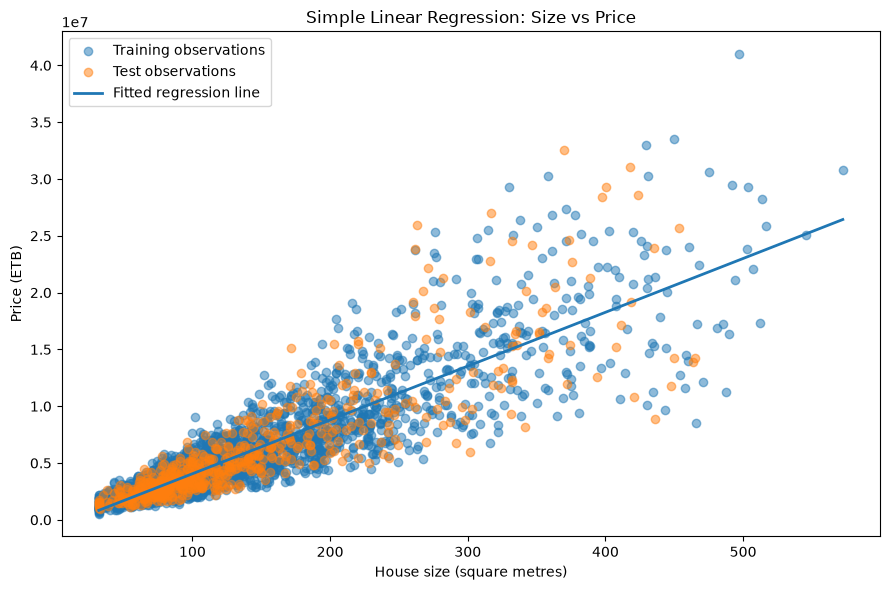

In [28]:
plt.figure(figsize=(9, 6))
plt.scatter(X_train[FEATURE], y_train, alpha=0.5, label="Training observations")
plt.scatter(X_test[FEATURE], y_test, alpha=0.5, label="Test observations")
x_line = np.linspace(float(X[FEATURE].min()), float(X[FEATURE].max()), 200).reshape(-1, 1)
y_line = slr.predict(pd.DataFrame(x_line, columns=[FEATURE]))
plt.plot(x_line, y_line, linewidth=2, label="Fitted regression line")
plt.xlabel("House size (square metres)")
plt.ylabel("Price (ETB)")
plt.title("Simple Linear Regression: Size vs Price")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Check residuals

A residual is actual value minus predicted value. Curved patterns or changing spread may suggest that a straight-line model is not sufficient.

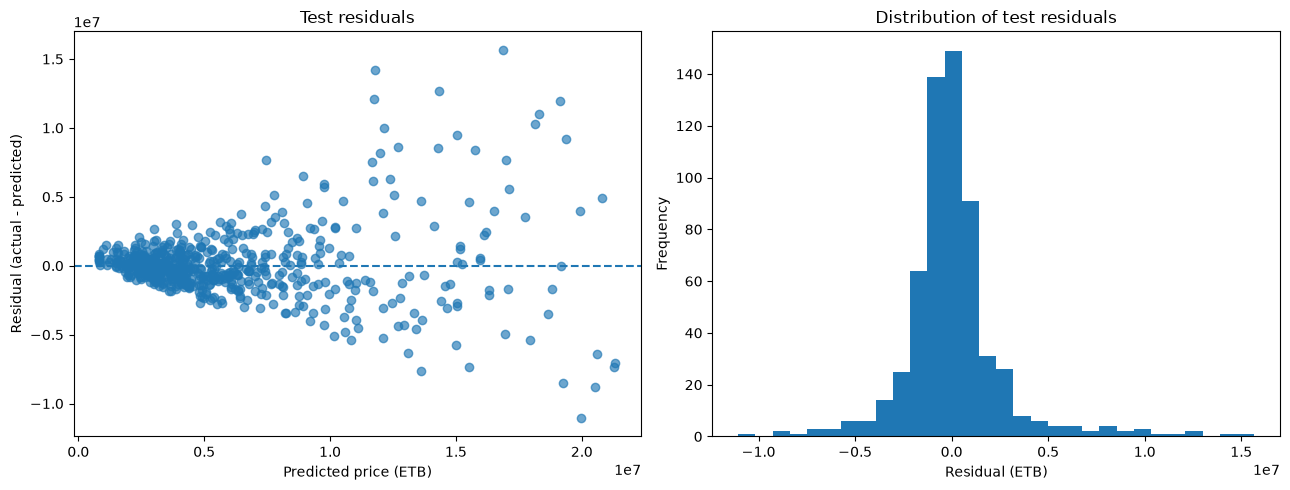

In [29]:
residuals = y_test.to_numpy() - np.asarray(test_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(test_pred, residuals, alpha=0.65)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted price (ETB)")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Test residuals")

axes[1].hist(residuals, bins=30)
axes[1].set_xlabel("Residual (ETB)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of test residuals")

plt.tight_layout()
plt.show()

## 9. Interpret the slope and results

- **Slope:** estimated average change in predicted price for a one-square-metre increase in size, within this fitted linear model.
- **Intercept:** predicted price when size is zero; it may not have a meaningful real-world interpretation.
- **Train vs test:** a large performance gap can indicate overfitting or a distribution difference, though simple linear regression often has limited flexibility.
- **Limitations:** one feature cannot capture every factor affecting house price, and association does not prove causation.

### Understanding check
1. What does the slope mean in this model?
2. Why do we evaluate on a test set?
3. What does a negative test R² mean?
4. Why might house size alone not predict price accurately?

## 10. Save the results

In [30]:
output_dir = Path("outputs") / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(output_dir / "01_slr_metrics.csv", index=False)
pd.DataFrame([{
    "feature": FEATURE,
    "target": TARGET,
    "intercept": intercept,
    "slope": slope,
    "train_rows": len(X_train),
    "test_rows": len(X_test),
}]).to_csv(output_dir / "01_slr_parameters.csv", index=False)

print("Saved outputs to:", output_dir.resolve())

Saved outputs to: C:\Users\hp\ML_Course\Notebooks\Regression\outputs\metrics
